# Digital Logic and CMOS Switching

This notebook separates two kinds of digital example:

1. **Electrical transistor-level switching:** a CMOS inverter netlist is imported and simulated through the supported nonlinear electrical transient solver.
2. **Functional logic reference models:** ideal 74HC-style gates, a D flip-flop and a serial-in/parallel-out shift register are stepped as discrete Boolean/state models.

The functional models are not connected to the MNA solver and do not model propagation delay, voltage thresholds, load, setup/hold, or metastability.

In [1]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
from examples.notebook_support import run_example, transient_trace, measure_signal
from circhecker.digital import LogicNetwork, inv, nand2, and2, or2, xor2, HC74, HC595

## 1. CMOS inverter: transistor-level transient simulation

The circuit uses one NMOS and one PMOS Level-1 model, a pulse input, and an output capacitance. This demonstrates electrical charge/discharge behavior in the supported device model, not sign-off timing for a standard-cell library.

In [2]:
cmos = run_example("cmos_inverter")
print(cmos.summary())
t, vin = transient_trace(cmos, node_name="in")
_, vout = transient_trace(cmos, node_name="out")
cmos_measurement = measure_signal(t, vout, name="CMOS inverter output")
print(f"Output minimum : {cmos_measurement.minimum:.4f} V")
print(f"Output maximum : {cmos_measurement.maximum:.4f} V")
print(f"Output p-p     : {cmos_measurement.peak_to_peak:.4f} V")

{'title': 'Complementary MOS inverter transient demonstration', 'status': 'success', 'validation_status': 'success', 'kcl_check': 'passed', 'backend': 'nonlinear_analog', 'analysis_status': {'dc_operating_point': 'success', 'dc_sweep': 'success', 'ac_sweep': 'success', 'transient': 'success', 'frequency_analysis': 'not_applicable', 'transfer_function': 'not_applicable', 'state_space': 'not_applicable'}, 'component_count': 5, 'node_count': 3, 'warnings': 0, 'errors': 0}
Output minimum : -0.4037 V
Output maximum : 5.4037 V
Output p-p     : 5.8073 V


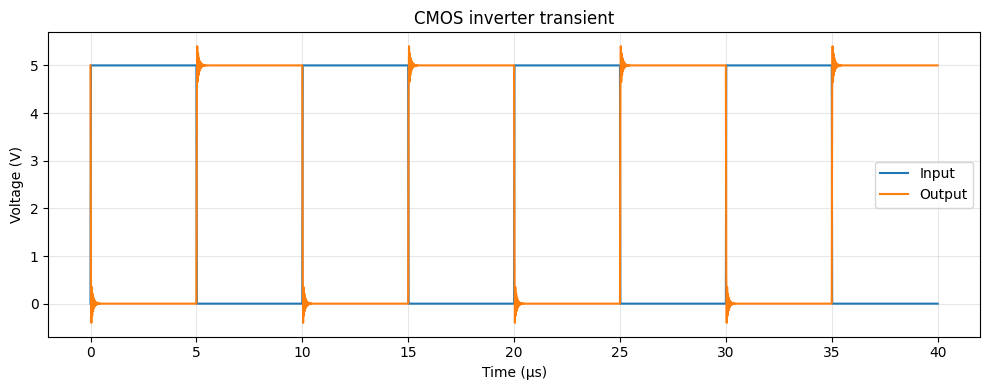

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t * 1e6, vin, label="Input")
ax.plot(t * 1e6, vout, label="Output")
ax.set(title="CMOS inverter transient", xlabel="Time (µs)", ylabel="Voltage (V)")
ax.grid(True, alpha=0.3); ax.legend(); fig.tight_layout(); plt.show()

## 2. Transistor-level CMOS NAND and NOR gates

These are electrical netlists, not ideal truth-table functions. Each gate is built from Level-1 NMOS/PMOS devices and a capacitive output load, then parsed into `CircuitIR` and solved by CirKreety's nonlinear transient backend. Sampled points are taken away from switching edges to compare settled output logic levels with the corresponding Boolean function.

In [4]:
nand = run_example("cmos_nand2")
nor = run_example("cmos_nor2")

logic_nand = LogicNetwork().add_gate("y", "NAND", "a", "b")
logic_nor = LogicNetwork().add_gate("y", "NOR", "a", "b")
print("NAND truth table:", logic_nand.truth_table(("a", "b"), ("y",)))
print("NOR truth table :", logic_nor.truth_table(("a", "b"), ("y",)))

sample_times_s = np.asarray([0.5, 2.5, 4.5, 6.5, 8.5, 10.5, 12.5, 14.5]) * 1e-6

def sample_gate(result, network, label):
    time_s, a_v = transient_trace(result, node_name="a")
    _, b_v = transient_trace(result, node_name="b")
    _, y_v = transient_trace(result, node_name="out")
    rows = []
    for sample_time in sample_times_s:
        index = int(np.argmin(np.abs(time_s - sample_time)))
        a_bit, b_bit = int(a_v[index] > 2.5), int(b_v[index] > 2.5)
        measured_y = int(y_v[index] > 2.5)
        expected_y = network.evaluate({"a": a_bit, "b": b_bit})["y"]
        rows.append({
            "t_us": round(float(time_s[index] * 1e6), 3),
            "A": a_bit, "B": b_bit,
            "Y_measured": measured_y, "Y_boolean": expected_y,
            "match": measured_y == expected_y,
        })
    metric = measure_signal(time_s, y_v, name=f"{label} output")
    print(f"{label}: output range {metric.minimum:.3f}..{metric.maximum:.3f} V; "
          f"p-p={metric.peak_to_peak:.3f} V; sampled Boolean matches "
          f"{sum(row['match'] for row in rows)}/{len(rows)}")
    for row in rows:
        print(row)
    return time_s, a_v, b_v, y_v

nand_wave = sample_gate(nand, logic_nand, "CMOS NAND")
nor_wave = sample_gate(nor, logic_nor, "CMOS NOR")

NAND truth table: [{'a': 0, 'b': 0, 'y': 1}, {'a': 0, 'b': 1, 'y': 1}, {'a': 1, 'b': 0, 'y': 1}, {'a': 1, 'b': 1, 'y': 0}]
NOR truth table : [{'a': 0, 'b': 0, 'y': 1}, {'a': 0, 'b': 1, 'y': 0}, {'a': 1, 'b': 0, 'y': 0}, {'a': 1, 'b': 1, 'y': 0}]
CMOS NAND: output range 0.000..5.359 V; p-p=5.359 V; sampled Boolean matches 8/8
{'t_us': 0.5, 'A': 1, 'B': 1, 'Y_measured': 0, 'Y_boolean': 0, 'match': True}
{'t_us': 2.5, 'A': 1, 'B': 0, 'Y_measured': 1, 'Y_boolean': 1, 'match': True}
{'t_us': 4.5, 'A': 0, 'B': 1, 'Y_measured': 1, 'Y_boolean': 1, 'match': True}
{'t_us': 6.5, 'A': 0, 'B': 0, 'Y_measured': 1, 'Y_boolean': 1, 'match': True}
{'t_us': 8.5, 'A': 1, 'B': 1, 'Y_measured': 0, 'Y_boolean': 0, 'match': True}
{'t_us': 10.5, 'A': 1, 'B': 0, 'Y_measured': 1, 'Y_boolean': 1, 'match': True}
{'t_us': 12.5, 'A': 0, 'B': 1, 'Y_measured': 1, 'Y_boolean': 1, 'match': True}
{'t_us': 14.5, 'A': 0, 'B': 0, 'Y_measured': 1, 'Y_boolean': 1, 'match': True}
CMOS NOR: output range -0.526..5.000 V; p-p=5.

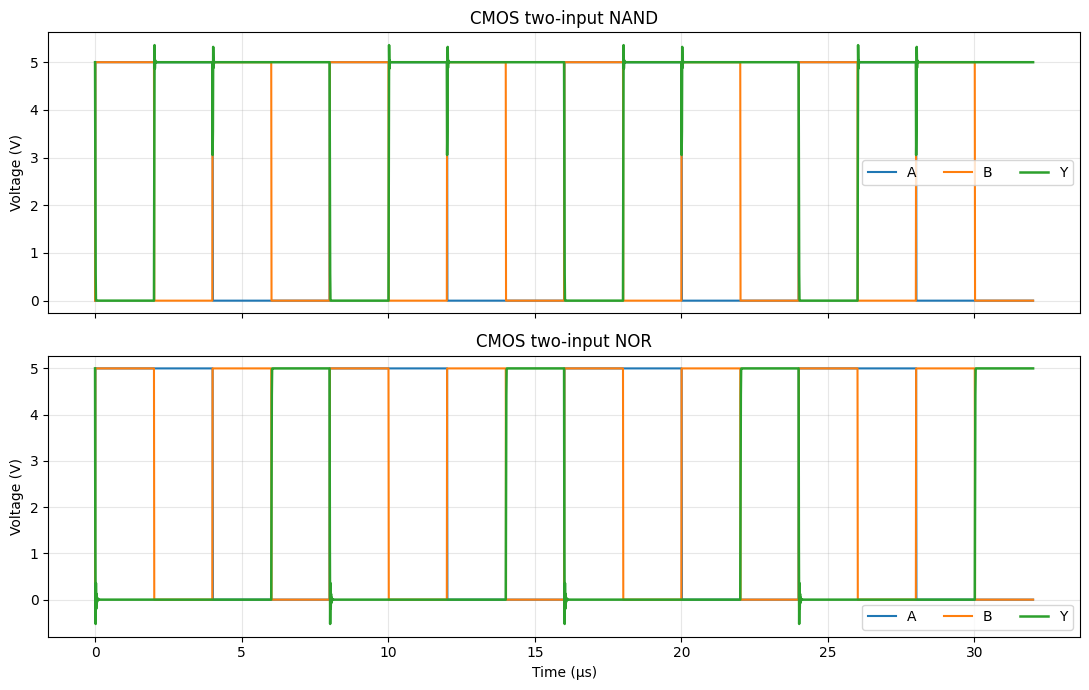

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for ax, traces, title in (
    (axes[0], nand_wave, "CMOS two-input NAND"),
    (axes[1], nor_wave, "CMOS two-input NOR"),
):
    time_s, a_v, b_v, y_v = traces
    ax.plot(time_s * 1e6, a_v, label="A")
    ax.plot(time_s * 1e6, b_v, label="B")
    ax.plot(time_s * 1e6, y_v, label="Y", linewidth=1.8)
    ax.set_ylabel("Voltage (V)")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend(ncol=3)
axes[-1].set_xlabel("Time (µs)")
fig.tight_layout()
plt.show()

## 3. Combinational network composition: a 2:1 multiplexer

`LogicNetwork` is a small, pure-Python functional network API. Gates can be declared in dependency order or in any order; the evaluator resolves their dependencies and detects missing wires and combinational cycles. This is a functional reference model with zero propagation delay, separate from the MNA engine.

In [6]:
mux = LogicNetwork()
mux.add_gate("not_sel", "NOT", "sel")
mux.add_gate("d0_selected", "AND", "d0", "not_sel")
mux.add_gate("d1_selected", "AND", "d1", "sel")
mux.add_gate("y", "OR", "d0_selected", "d1_selected")
mux_rows = mux.truth_table(("d0", "d1", "sel"), ("y",))
for row in mux_rows:
    print(row)
assert mux.evaluate({"d0": 1, "d1": 0, "sel": 0})["y"] == 1
assert mux.evaluate({"d0": 1, "d1": 0, "sel": 1})["y"] == 0

{'d0': 0, 'd1': 0, 'sel': 0, 'y': 0}
{'d0': 0, 'd1': 0, 'sel': 1, 'y': 0}
{'d0': 0, 'd1': 1, 'sel': 0, 'y': 0}
{'d0': 0, 'd1': 1, 'sel': 1, 'y': 1}
{'d0': 1, 'd1': 0, 'sel': 0, 'y': 1}
{'d0': 1, 'd1': 0, 'sel': 1, 'y': 0}
{'d0': 1, 'd1': 1, 'sel': 0, 'y': 1}
{'d0': 1, 'd1': 1, 'sel': 1, 'y': 1}


## 4. Ideal 74HC-style combinational logic reference tables

These Python functions implement Boolean truth tables only. They are useful for logic-level test vectors and do not imply analog electrical simulation of a 74HC IC.

In [7]:
truth_rows = []
for a, b in itertools.product((0, 1), repeat=2):
    truth_rows.append({"A": a, "B": b, "NAND": nand2(a, b), "AND": and2(a, b), "OR": or2(a, b), "XOR": xor2(a, b)})
for row in truth_rows:
    print(row)
print("NOT truth table:", [(a, inv(a)) for a in (0, 1)])

{'A': 0, 'B': 0, 'NAND': 1, 'AND': 0, 'OR': 0, 'XOR': 0}
{'A': 0, 'B': 1, 'NAND': 1, 'AND': 0, 'OR': 1, 'XOR': 1}
{'A': 1, 'B': 0, 'NAND': 1, 'AND': 0, 'OR': 1, 'XOR': 1}
{'A': 1, 'B': 1, 'NAND': 0, 'AND': 1, 'OR': 1, 'XOR': 0}
NOT truth table: [(0, 1), (1, 0)]


## 5. 74HC74-style positive-edge D flip-flop

The model updates Q on a rising clock edge and supports asynchronous active-low clear/preset. It rejects the invalid condition where both controls are low.

In [8]:
flipflop = HC74()
clock = [0, 1, 0, 1, 0, 1, 0, 1]
data =  [1, 1, 1, 0, 0, 1, 1, 0]
q_trace = []
qbar_trace = []
for clk, d in zip(clock, data):
    q, qbar = flipflop.step(clock=clk, d=d)
    q_trace.append(q); qbar_trace.append(qbar)
print("Clock samples:", clock)
print("D samples    :", data)
print("Q samples    :", q_trace)

Clock samples: [0, 1, 0, 1, 0, 1, 0, 1]
D samples    : [1, 1, 1, 0, 0, 1, 1, 0]
Q samples    : [0, 1, 1, 0, 0, 1, 1, 0]


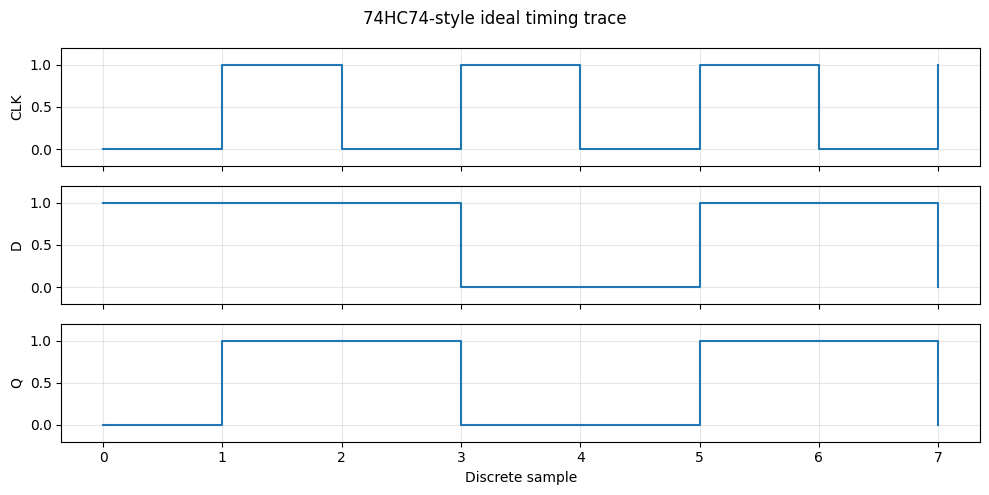

In [9]:
sample = np.arange(len(clock))
fig, axes = plt.subplots(3, 1, figsize=(10, 5), sharex=True)
for ax, values, label in zip(axes, (clock, data, q_trace), ("CLK", "D", "Q")):
    ax.step(sample, values, where="post")
    ax.set_ylabel(label); ax.set_ylim(-0.2, 1.2); ax.grid(True, alpha=0.3)
axes[-1].set_xlabel("Discrete sample")
fig.suptitle("74HC74-style ideal timing trace"); fig.tight_layout(); plt.show()

## 6. 74HC595-style shift register

Eight serial bits are shifted on rising edges, then copied to the output register on the rising latch edge. Output enable is active-low.

In [10]:
shift_register = HC595()
serial_bits = [1, 0, 1, 0, 0, 1, 0, 1]
shift_states = []
for bit in serial_bits:
    shift_register.step(shift_clock=0, serial_data=bit, latch_clock=0)
    shift_register.step(shift_clock=1, serial_data=bit, latch_clock=0)
    shift_states.append(shift_register.shift_register)
    shift_register.step(shift_clock=0, serial_data=bit, latch_clock=0)
latched_outputs = shift_register.step(shift_clock=0, serial_data=0, latch_clock=1)
print("Serial input pattern :", "".join(map(str, serial_bits)))
print("Shift-register state :", format(shift_register.shift_register, "08b"))
print("Latched parallel out :", "".join(str(bit) for bit in latched_outputs))

Serial input pattern : 10100101
Shift-register state : 10100101
Latched parallel out : 10100101


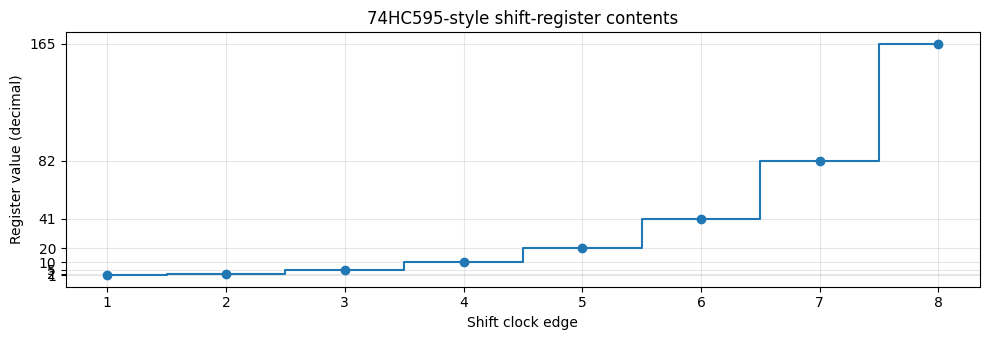

In [11]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.step(np.arange(1, 9), shift_states, where="mid", marker="o")
ax.set(title="74HC595-style shift-register contents", xlabel="Shift clock edge", ylabel="Register value (decimal)")
ax.set_yticks(shift_states); ax.grid(True, alpha=0.3); fig.tight_layout(); plt.show()

## Model boundary

The CMOS inverter is an electrical simulation of a small transistor-level circuit with a compact model. The 74HC-style Python objects are ideal functional references. A mixed-signal simulator that co-simulates arbitrary digital state machines with nonlinear analog MNA, and accurate commercial-chip electrical models, are future extension areas.

In [12]:
print("CMOS analysis statuses:", cmos.summary()["analysis_status"])
print("CMOS artifacts:", cmos.artifacts)

CMOS analysis statuses: {'dc_operating_point': 'success', 'dc_sweep': 'success', 'ac_sweep': 'success', 'transient': 'success', 'frequency_analysis': 'not_applicable', 'transfer_function': 'not_applicable', 'state_space': 'not_applicable'}
CMOS artifacts: {'example_id': 'cmos_inverter', 'input_netlist': 'examples/circuits/digital/cmos_inverter.cir', 'circuit_ir_json': 'reports/notebook_examples/cmos_inverter/circuit_ir.json', 'plot': 'reports/notebook_examples/cmos_inverter/review.png', 'analysis_json': 'reports/notebook_examples/cmos_inverter/analysis.json'}
